# Selectivity Matrix, Register Vocabulary, and Isolated Folios

Three final analyses:
- **Part A**: The real onset x coda selectivity matrix — which combinations are allowed
- **Part B**: Language A vs B exclusive vocabulary — technical vs functional lexicons
- **Part C**: The 16 isolated folios — what makes them unique

In [15]:
# Cell 1 — Imports
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter, defaultdict
from pathlib import Path
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.spatial.distance import pdist

sns.set_style('whitegrid')
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 150,
                     'font.size': 9, 'axes.titlesize': 11})
Path('images').mkdir(exist_ok=True)
Path('resultados').mkdir(exist_ok=True)
print('Imports OK')

Imports OK


In [16]:
# Cell 2 — Parse STA1 with metadata + TP-P20 pipeline (self-contained, same as nb47 cell 2+4)

STA_PATH = "corpus/voynich_sta.txt"

# ── Parse STA1 corpus ──
folio_data = {}
current_folio = None

with open(STA_PATH, "r") as f:
    for line in f:
        line = line.strip()
        if not line or line.startswith("#"):
            continue
        hdr_match = re.match(r"^<([^>]+)>\s+<!", line)
        if hdr_match:
            current_folio = hdr_match.group(1)
            meta = {}
            for key in ("I", "L", "H"):
                m = re.search(rf"\$({key})=(\S+)", line)
                if m:
                    meta[key] = m.group(2)
            folio_data[current_folio] = {"meta": meta, "words": []}
            continue
        txt_match = re.match(r"^<[^>]+>\s+(.*)", line)
        if txt_match and current_folio:
            text_part = txt_match.group(1)
            text_part = re.sub(r"\{[^}]*\}", "", text_part)
            text_part = re.sub(r"<->", ".", text_part)
            chunks = re.split(r"[.\-]", text_part)
            for chunk in chunks:
                chunk = chunk.strip().rstrip(",")
                if not chunk:
                    continue
                glyphs = re.findall(r"[A-Z][0-9a-z]", chunk)
                if glyphs:
                    folio_data[current_folio]["words"].append(glyphs)

# ── TP-P20 pipeline ──
all_words = [w for fd in folio_data.values() for w in fd['words']]
VOCAB = sorted(set(g for w in all_words for g in w))
idx_map = {g: i for i, g in enumerate(VOCAB)}
nv = len(VOCAB)
M = np.zeros((nv, nv))
for w in all_words:
    for i in range(len(w)-1):
        M[idx_map[w[i]], idx_map[w[i+1]]] += 1
rs = M.sum(axis=1, keepdims=True)
rs[rs == 0] = 1
M_prob = M / rs

all_tp = []
for w in all_words:
    for i in range(len(w)-1):
        all_tp.append(M_prob[idx_map[w[i]], idx_map[w[i+1]]])
thr = np.percentile(all_tp, 20)

def segment(w):
    syls, s = [], [w[0]]
    for i in range(len(w)-1):
        p = M_prob[idx_map[w[i]], idx_map[w[i+1]]] if (w[i] in idx_map and w[i+1] in idx_map) else 0
        if p < thr:
            syls.append(tuple(s))
            s = [w[i+1]]
        else:
            s.append(w[i+1])
    if s:
        syls.append(tuple(s))
    return syls

syl_pos = defaultdict(lambda: {'s':0, 'm':0, 'e':0, 't':0})
for w in all_words:
    syls = segment(w)
    ns = len(syls)
    for i, syl in enumerate(syls):
        syl_pos[syl]['t'] += 1
        if ns == 1:
            syl_pos[syl]['s'] += 1
            syl_pos[syl]['e'] += 1
        elif i == 0:
            syl_pos[syl]['s'] += 1
        elif i == ns - 1:
            syl_pos[syl]['e'] += 1
        else:
            syl_pos[syl]['m'] += 1

clase = {}
for syl, c in syl_pos.items():
    if c['t'] < 5:
        continue
    r_s = c['s'] / c['t']
    r_e = c['e'] / c['t']
    r_m = c['m'] / c['t']
    if r_s >= 0.6 and r_e < 0.3:
        clase[syl] = 'onset'
    elif r_e >= 0.6 and r_s < 0.3:
        clase[syl] = 'coda'
    elif r_m >= 0.4:
        clase[syl] = 'nuclear'
    else:
        clase[syl] = 'free'

def word_tier(w):
    syls = segment(w)
    pat = '-'.join(clase.get(s, '?') for s in syls)
    abbr = pat.replace('onset','O').replace('nuclear','N').replace('coda','C').replace('free','F')
    if '?' in abbr:
        return '?', abbr
    if abbr == 'F':
        return 'T1', abbr
    return 'T2', abbr

n_o = sum(1 for v in clase.values() if v == 'onset')
n_c = sum(1 for v in clase.values() if v == 'coda')
n_n = sum(1 for v in clase.values() if v == 'nuclear')
n_f = sum(1 for v in clase.values() if v == 'free')
tier_counts = Counter(word_tier(w)[0] for w in all_words)

print(f"Folios: {len(folio_data)}, Words: {len(all_words):,}, Glyphs: {sum(len(w) for w in all_words):,}")
print(f"TP threshold (P20): {thr:.4f}")
print(f"Syllable types: {len(clase)} (O={n_o}, N={n_n}, C={n_c}, F={n_f})")
print(f"Tier distribution: {dict(tier_counts)}")

Folios: 227, Words: 37,848, Glyphs: 157,254
TP threshold (P20): 0.0902
Syllable types: 773 (O=165, N=49, C=88, F=471)
Tier distribution: {'T2': 18246, 'T1': 16894, '?': 2708}


## Part A: Selectivity Matrix

In [17]:
# Cell 3 — Build the REAL onset x coda frequency matrix
# For every O-C word, record (onset_syllable, coda_syllable) pairs.

oc_pairs = Counter()
for w in all_words:
    syls = segment(w)
    if len(syls) < 2:
        continue
    c0 = clase.get(syls[0])
    c1 = clase.get(syls[-1])
    if c0 == 'onset' and c1 == 'coda':
        oc_pairs[(syls[0], syls[-1])] += 1

# Build matrix with string labels
onset_syls = sorted(set(o for o, c in oc_pairs), key=lambda s: '.'.join(s))
coda_syls = sorted(set(c for o, c in oc_pairs), key=lambda s: '.'.join(s))

onset_labels = ['.'.join(s) for s in onset_syls]
coda_labels = ['.'.join(s) for s in coda_syls]

freq_matrix = pd.DataFrame(0, index=onset_labels, columns=coda_labels)
for (o, c), n in oc_pairs.items():
    freq_matrix.loc['.'.join(o), '.'.join(c)] = n

# Filter to functional types (freq >= 5 for the syllable across corpus)
onset_keep = [s for s in onset_syls if syl_pos[s]['t'] >= 5]
coda_keep = [s for s in coda_syls if syl_pos[s]['t'] >= 5]
onset_labels_k = ['.'.join(s) for s in onset_keep]
coda_labels_k = ['.'.join(s) for s in coda_keep]
freq_filtered = freq_matrix.loc[onset_labels_k, coda_labels_k]

total_combos = len(onset_labels_k) * len(coda_labels_k)
observed = (freq_filtered > 0).sum().sum()
sparsity = 1 - observed / total_combos if total_combos > 0 else 0

print(f"O-C pairs observed: {len(oc_pairs):,} types, {sum(oc_pairs.values()):,} tokens")
print(f"Onset syllables (freq>=5): {len(onset_labels_k)}")
print(f"Coda syllables (freq>=5):  {len(coda_labels_k)}")
print(f"Matrix: {len(onset_labels_k)} x {len(coda_labels_k)} = {total_combos} cells")
print(f"Non-zero cells: {observed} ({observed/total_combos*100:.1f}%)")
print(f"Sparsity: {sparsity*100:.1f}%")
print()

# Top 10 most frequent pairs
print("Top 10 onset-coda pairs:")
for (o, c), n in oc_pairs.most_common(10):
    print(f"  {'.'.join(o):>12} + {'.'.join(c):<12}  freq={n}")

O-C pairs observed: 1,357 types, 8,053 tokens
Onset syllables (freq>=5): 164
Coda syllables (freq>=5):  87
Matrix: 164 x 87 = 14268 cells
Non-zero cells: 1357 (9.5%)
Sparsity: 90.5%

Top 10 onset-coda pairs:
            K1 + K2.A2         freq=171
            K1 + B1.A2         freq=151
      D1.A1.Q1 + A2            freq=147
            K1 + U1.A2         freq=133
         A1.Q1 + A2            freq=121
         A1.Q2 + A2            freq=117
            A1 + B1.A2         freq=109
         K1.J1 + A2            freq=100
            L1 + A2            freq=99
         K1.A1 + B1.A2         freq=89


Binary matrix for clustering: 164 onsets x 87 codas


/home/cesar/Documentos/Code/LLM_training/.venv/lib/python3.12/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
/home/cesar/Documentos/Code/LLM_training/.venv/lib/python3.12/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


Saved: images/selectivity_matrix.png


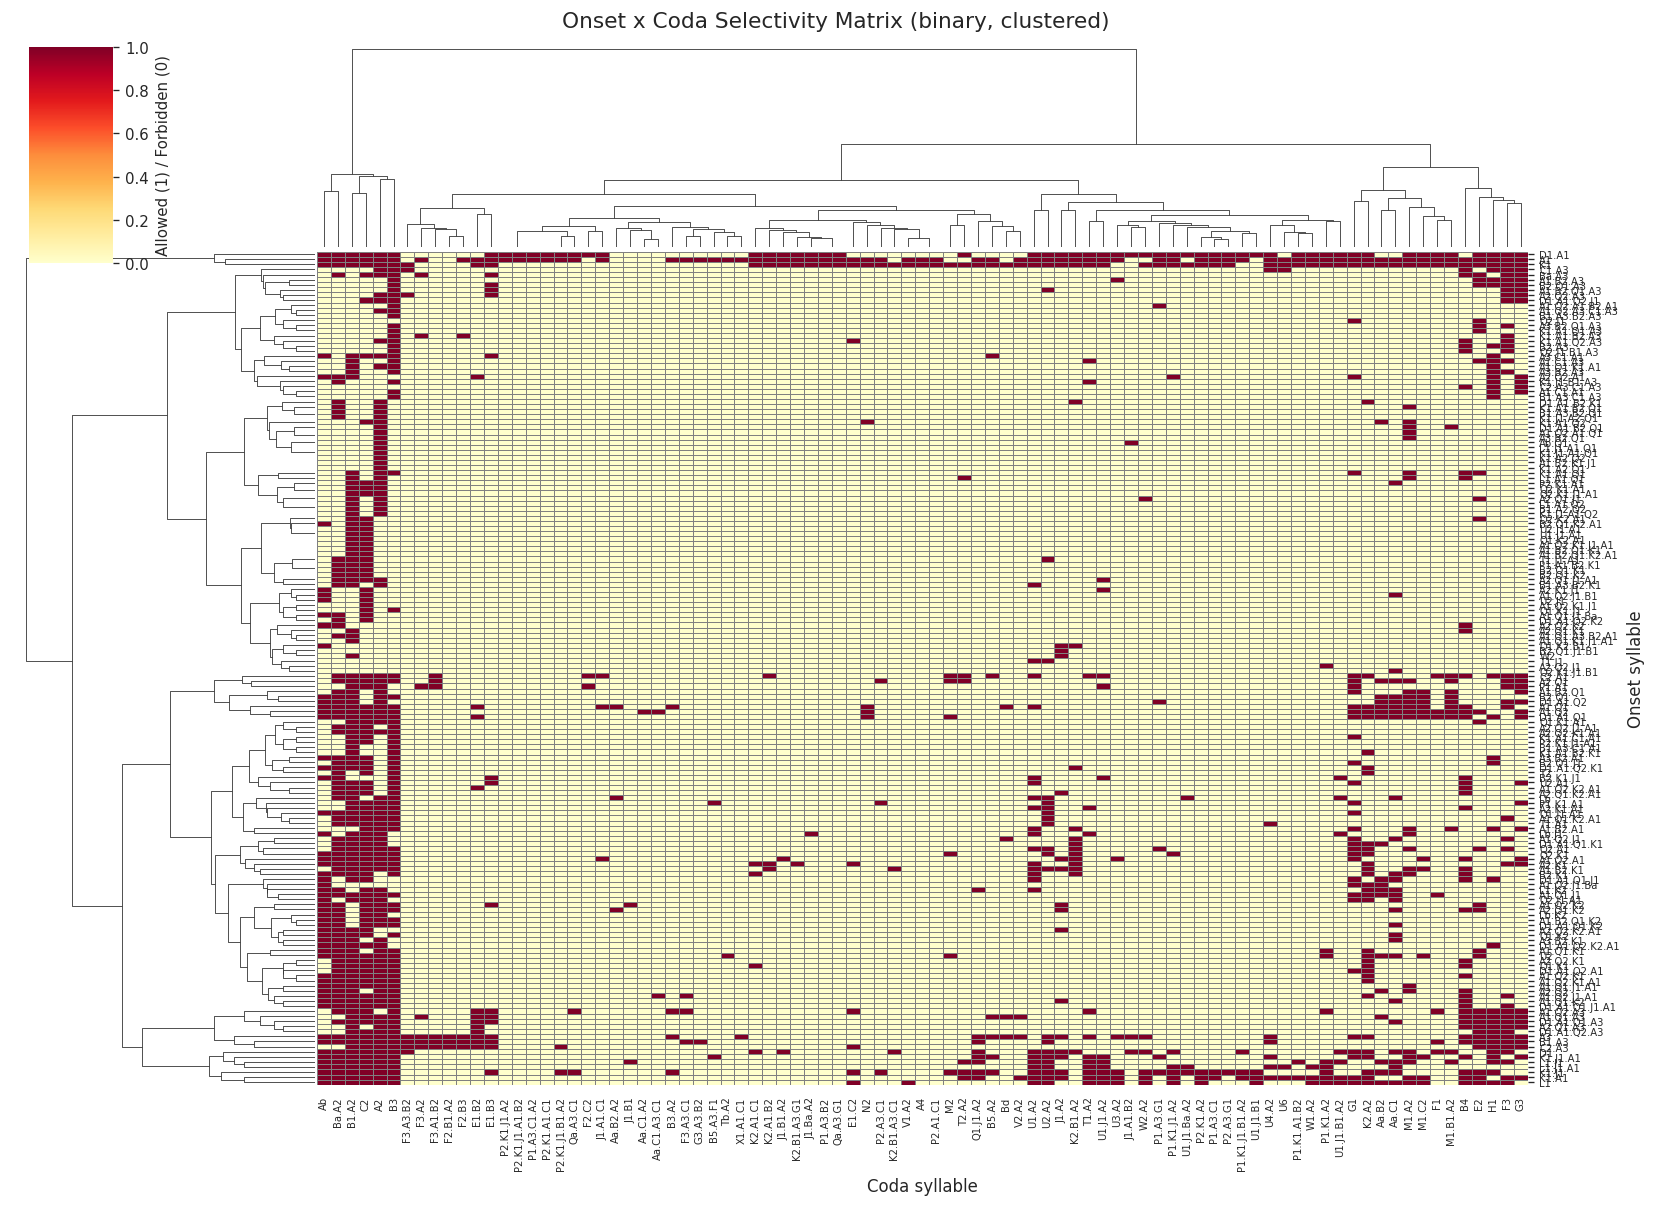

In [18]:
# Cell 4 — Clustered heatmap of binary selectivity matrix
# Binary version: 1 if combo exists, 0 if not. Ward's method clustering.

binary_matrix = (freq_filtered > 0).astype(int)

# Drop rows/cols that are all-zero (if any)
binary_matrix = binary_matrix.loc[binary_matrix.sum(axis=1) > 0, binary_matrix.sum(axis=0) > 0]

print(f"Binary matrix for clustering: {binary_matrix.shape[0]} onsets x {binary_matrix.shape[1]} codas")

# Use euclidean distance + Ward's method for clustermap
g = sns.clustermap(binary_matrix, method='ward', metric='euclidean',
                   cmap='YlOrRd', figsize=(14, 10),
                   linewidths=0.3, linecolor='grey',
                   xticklabels=True, yticklabels=True,
                   cbar_kws={'label': 'Allowed (1) / Forbidden (0)'})
g.ax_heatmap.set_xlabel('Coda syllable', fontsize=10)
g.ax_heatmap.set_ylabel('Onset syllable', fontsize=10)
g.fig.suptitle('Onset x Coda Selectivity Matrix (binary, clustered)', fontsize=13, y=1.01)
g.ax_heatmap.tick_params(axis='both', labelsize=6)

g.savefig('images/selectivity_matrix.png', bbox_inches='tight', dpi=150)
print("Saved: images/selectivity_matrix.png")
plt.show()

In [19]:
# Cell 5 — Extract onset blocks from clustering
# Cut dendrogram to get 5-15 groups of onsets that share similar coda selectivity.

# Re-compute linkage on onsets (rows)
X_rows = binary_matrix.values.astype(float)
if X_rows.shape[0] > 1:
    dist_rows = pdist(X_rows, metric='euclidean')
    Z_rows = linkage(dist_rows, method='ward')

    # Try different cuts to get 5-15 groups
    for n_cut in range(8, 4, -1):
        labels_cut = fcluster(Z_rows, t=n_cut, criterion='maxclust')
        n_groups = len(set(labels_cut))
        if 5 <= n_groups <= 15:
            break

    onset_names = list(binary_matrix.index)
    onset_groups = defaultdict(list)
    for i, lbl in enumerate(labels_cut):
        onset_groups[lbl].append(onset_names[i])

    # For each group, find their shared codas and dominant section
    # Build onset -> section mapping from corpus
    onset_section = defaultdict(Counter)
    for folio, fd in folio_data.items():
        itype = fd['meta'].get('I', '?')
        for w in fd['words']:
            syls = segment(w)
            if syls and clase.get(syls[0]) == 'onset':
                onset_section['.'.join(syls[0])][itype] += 1

    print(f"Onset blocks: {n_groups} groups from dendrogram cut at maxclust={n_cut}")
    print(f"{'='*80}")
    for grp in sorted(onset_groups.keys()):
        members = onset_groups[grp]
        # Shared codas: codas that ALL members in this group can take
        shared = set(binary_matrix.columns)
        for m in members:
            shared &= set(binary_matrix.columns[binary_matrix.loc[m] == 1])
        # Dominant section
        sec_counts = Counter()
        for m in members:
            sec_counts.update(onset_section.get(m, {}))
        dom_sec = sec_counts.most_common(1)[0][0] if sec_counts else '?'
        # Example words: first member + any coda
        ex_onset = members[0]
        ex_codas = [c for c in binary_matrix.columns if binary_matrix.loc[ex_onset, c] == 1]
        example = f"{ex_onset}+{ex_codas[0]}" if ex_codas else ex_onset

        print(f"\nGroup {grp} ({len(members)} onsets) — dominant section: ${dom_sec}")
        print(f"  Onsets: {', '.join(members[:8])}{'...' if len(members)>8 else ''}")
        print(f"  Shared codas ({len(shared)}): {', '.join(sorted(shared)[:6])}{'...' if len(shared)>6 else ''}")
        print(f"  Example: {example}")
else:
    print("Only 1 onset — no clustering possible")

Onset blocks: 8 groups from dendrogram cut at maxclust=8

Group 1 (3 onsets) — dominant section: $S
  Onsets: A1, D1.A1, K1
  Shared codas (40): A2, Ab, B1.A2, B3, Ba.A2, C2...
  Example: A1+A2

Group 2 (26 onsets) — dominant section: $S
  Onsets: A1.B2.A3, A1.B2.Q1.A3, A1.C1.A1, A1.C1.A3, A1.Q1.K1.A1, A1.Q2.A1.B2.A1, A1.Q2.A3.C1.A3, A2.Q2.A1...
  Shared codas (0): 
  Example: A1.B2.A3+B3

Group 3 (23 onsets) — dominant section: $H
  Onsets: A1.B2.K1.J1, A1.Q2.A1.Q1, A2.Q1.J1, A3.B2.Q1, Ab.Q1, B1.A2.Q2, B1.A3.B2.Q1, D1.A1.B2.K1...
  Shared codas (1): A2
  Example: A1.B2.K1.J1+A2

Group 4 (31 onsets) — dominant section: $S
  Onsets: A1.B2.Q1.K1, A1.B2.Q1.K2.A1, A1.Q1.A3.B2.A1, A1.Q1.J1.Ba, A1.Q1.K1.J1.A1, A1.Q2.J1.B1, A1.Q2.K1.J1, A1.Q2.K1.J1.A1...
  Shared codas (0): 
  Example: A1.B2.Q1.K1+B1.A2

Group 5 (9 onsets) — dominant section: $H
  Onsets: A1.B2.Q1, A1.Q1, A1.Q2, A2.Q1, B2.Q1, C2.A1, D1.A1.Q1, D1.A1.Q2...
  Shared codas (2): A2, B1.A2
  Example: A1.B2.Q1+A2

Group 6 (57 onsets

## Part B: Language A vs B Exclusive Vocabulary

In [20]:
# Cell 6 — Separate A-only, B-only, and shared words
# For each unique word type (as tuple), count occurrences in Language A vs B folios.

word_counts_A = Counter()
word_counts_B = Counter()

for folio, fd in folio_data.items():
    lang = fd['meta'].get('L', '?')
    for w in fd['words']:
        wt = tuple(w)
        if lang == 'A':
            word_counts_A[wt] += 1
        elif lang == 'B':
            word_counts_B[wt] += 1

all_types = set(word_counts_A.keys()) | set(word_counts_B.keys())
a_only = {wt for wt in all_types if word_counts_A[wt] > 0 and word_counts_B[wt] == 0}
b_only = {wt for wt in all_types if word_counts_B[wt] > 0 and word_counts_A[wt] == 0}
shared = {wt for wt in all_types if word_counts_A[wt] > 0 and word_counts_B[wt] > 0}

# Token counts
a_only_tokens = sum(word_counts_A[wt] for wt in a_only)
b_only_tokens = sum(word_counts_B[wt] for wt in b_only)
shared_tokens_A = sum(word_counts_A[wt] for wt in shared)
shared_tokens_B = sum(word_counts_B[wt] for wt in shared)
total_A = sum(word_counts_A.values())
total_B = sum(word_counts_B.values())

print(f"Language A: {total_A:,} tokens, {len(word_counts_A):,} types")
print(f"Language B: {total_B:,} tokens, {len(word_counts_B):,} types")
print()
print(f"{'Category':<12} {'Types':>7} {'%types':>7}  {'Tokens A':>9} {'Tokens B':>9}")
print('-' * 52)
print(f"{'A-only':<12} {len(a_only):>7} {len(a_only)/len(all_types)*100:>6.1f}%  {a_only_tokens:>9,} {'—':>9}")
print(f"{'B-only':<12} {len(b_only):>7} {len(b_only)/len(all_types)*100:>6.1f}%  {'—':>9} {b_only_tokens:>9,}")
print(f"{'Shared':<12} {len(shared):>7} {len(shared)/len(all_types)*100:>6.1f}%  {shared_tokens_A:>9,} {shared_tokens_B:>9,}")
print()

# Examples
print("Examples of A-only words (top 5 by freq):")
for wt, n in sorted(a_only, key=lambda x: word_counts_A[x], reverse=True)[:5] if False else Counter({wt: word_counts_A[wt] for wt in a_only}).most_common(5):
    print(f"  {'.'.join(wt):<25} freq={n}")

print("\nExamples of B-only words (top 5 by freq):")
for wt, n in Counter({wt: word_counts_B[wt] for wt in b_only}).most_common(5):
    print(f"  {'.'.join(wt):<25} freq={n}")

print("\nExamples of shared words (top 5 by total freq):")
for wt, n in Counter({wt: word_counts_A[wt]+word_counts_B[wt] for wt in shared}).most_common(5):
    print(f"  {'.'.join(wt):<25} freqA={word_counts_A[wt]}, freqB={word_counts_B[wt]}")

Language A: 11,178 tokens, 3,867 types
Language B: 23,491 tokens, 6,114 types

Category       Types  %types   Tokens A  Tokens B
----------------------------------------------------
A-only          2711   30.7%      3,376         —
B-only          4958   56.2%          —     9,424
Shared          1156   13.1%      7,802    14,067

Examples of A-only words (top 5 by freq):
  D1.A1.Q2.K1.A1.B2         freq=14
  K1.A1.B3                  freq=14
  U2.A1.B1.A2               freq=13
  D1.A1.Q2.K1.A1.C1         freq=12
  U2.A3.G1                  freq=12

Examples of B-only words (top 5 by freq):
  D1.A1.Q1.K2.B1.A2         freq=221
  D1.A1.Q1.J1.B1.A2         freq=175
  K1.J1.Ba.A2               freq=154
  L1.J1.Ba.A2               freq=108
  A1.Q2.J1.B1.A2            freq=91

Examples of shared words (top 5 by total freq):
  B1.A3.G1                  freqA=426, freqB=257
  A1.B2                     freqA=98, freqB=392
  A3.G1                     freqA=76, freqB=343
  K1.A1.B2              

In [21]:
# Cell 7 — A-only vs B-only tier analysis
# Are A-only words more T2 (content) and B-only more T1 (functional)?

def tier_breakdown(word_set, freq_dict):
    """Compute %F and %OC for a set of word types, weighted by frequency."""
    tier_c = Counter()
    pat_c = Counter()
    for wt in word_set:
        t, pat = word_tier(list(wt))
        freq = freq_dict[wt]
        tier_c[t] += freq
        pat_c[pat] += freq
    total = sum(tier_c.values())
    if total == 0:
        return {'n': 0, 'pct_F': 0, 'pct_OC': 0, 'pct_T1': 0, 'pct_T2': 0, 'pct_unk': 0}
    return {
        'n': total,
        'pct_F': pat_c.get('F', 0) / total,
        'pct_OC': pat_c.get('O-C', 0) / total,
        'pct_T1': tier_c.get('T1', 0) / total,
        'pct_T2': tier_c.get('T2', 0) / total,
        'pct_unk': tier_c.get('?', 0) / total,
    }

tb_a = tier_breakdown(a_only, word_counts_A)
tb_b = tier_breakdown(b_only, word_counts_B)
tb_shared_A = tier_breakdown(shared, word_counts_A)
tb_shared_B = tier_breakdown(shared, word_counts_B)

print(f"{'Group':<14} {'N tokens':>9} {'%T1':>7} {'%T2':>7} {'%?':>7} {'%F':>7} {'%O-C':>7}")
print('-' * 65)
for label, tb in [('A-only', tb_a), ('B-only', tb_b),
                  ('Shared(A)', tb_shared_A), ('Shared(B)', tb_shared_B)]:
    print(f"{label:<14} {tb['n']:>9,} {tb['pct_T1']*100:>6.1f}% {tb['pct_T2']*100:>6.1f}% "
          f"{tb['pct_unk']*100:>6.1f}% {tb['pct_F']*100:>6.1f}% {tb['pct_OC']*100:>6.1f}%")

print()
print("Interpretation:")
if tb_a['pct_T2'] > tb_b['pct_T2']:
    print("  A-only vocabulary is MORE content-rich (T2) than B-only")
else:
    print("  B-only vocabulary is MORE content-rich (T2) than A-only")
if tb_a['pct_F'] < tb_b['pct_F']:
    print("  B-only vocabulary is MORE functional (F) than A-only")
else:
    print("  A-only vocabulary is MORE functional (F) than B-only")

Group           N tokens     %T1     %T2      %?      %F    %O-C
-----------------------------------------------------------------
A-only             3,376    4.5%   74.6%   21.0%    4.5%    9.0%
B-only             9,424   25.2%   59.1%   15.7%   25.2%   14.2%
Shared(A)          7,802   53.7%   45.3%    1.0%   53.7%   15.8%
Shared(B)         14,067   65.5%   33.9%    0.6%   65.5%   17.1%

Interpretation:
  A-only vocabulary is MORE content-rich (T2) than B-only
  B-only vocabulary is MORE functional (F) than A-only


In [22]:
# Cell 8 — Top exclusive words per register
# Top 20 A-only and B-only words with tier, pattern, and dominant $I type.

type_names = {'H':'Herbal','A':'Astronomical','B':'Biological','C':'Cosmological',
              'P':'Pharmaceutical','S':'Stars','T':'Text-only','Z':'Zodiac'}

# Build word -> dominant $I mapping
word_section = defaultdict(Counter)
for folio, fd in folio_data.items():
    itype = fd['meta'].get('I', '?')
    for w in fd['words']:
        word_section[tuple(w)][itype] += 1

def show_top_words(word_set, freq_dict, label, n=20):
    top = Counter({wt: freq_dict[wt] for wt in word_set}).most_common(n)
    print(f"\nTop {n} {label} words:")
    print(f"  {'Word':<25} {'Freq':>5} {'Tier':<4} {'Pattern':<12} {'Section':<14}")
    print(f"  {'-'*65}")
    for wt, freq in top:
        t, pat = word_tier(list(wt))
        dom_I = word_section[wt].most_common(1)[0][0] if word_section[wt] else '?'
        sec_name = type_names.get(dom_I, dom_I)
        print(f"  {'.'.join(wt):<25} {freq:>5} {t:<4} {pat:<12} {sec_name:<14}")

show_top_words(a_only, word_counts_A, "A-only (description vocabulary)")
show_top_words(b_only, word_counts_B, "B-only (instruction vocabulary)")


Top 20 A-only (description vocabulary) words:
  Word                       Freq Tier Pattern      Section       
  -----------------------------------------------------------------
  D1.A1.Q2.K1.A1.B2            14 T1   F            Herbal        
  K1.A1.B3                     14 T2   O-C          Herbal        
  U2.A1.B1.A2                  13 T2   O-C          Herbal        
  D1.A1.Q2.K1.A1.C1            12 T1   F            Herbal        
  U2.A3.G1                     12 T2   O-F          Herbal        
  K1.A1.C1.A2                  11 T1   F            Herbal        
  K1.A1.Q2.K1.A2               11 T1   F            Herbal        
  U2.J1.A1.B2                  10 T1   F            Pharmaceutical
  A1.Q1.K1.A1.B2               10 T1   F            Herbal        
  K1.A1.G1                     10 T2   O-C          Herbal        
  U2.A1                        10 T2   O            Herbal        
  U1.A1.C1                      8 T1   F            Herbal        
  B1.L1.A1    

In [23]:
# Cell 9 — A/B vocabulary overlap by $I type (Jaccard similarity)
# Which illustration types have the MOST overlap and which the LEAST?

vocab_by_IL = defaultdict(lambda: {'A': set(), 'B': set()})
for folio, fd in folio_data.items():
    itype = fd['meta'].get('I', '?')
    lang = fd['meta'].get('L', '?')
    if lang in ('A', 'B'):
        for w in fd['words']:
            vocab_by_IL[itype][lang].add(tuple(w))

print(f"{'$I type':<16} {'|V_A|':>7} {'|V_B|':>7} {'|Shared|':>8} {'Jaccard':>8}")
print('-' * 52)
jaccard_by_I = {}
for itype in sorted(vocab_by_IL.keys()):
    va = vocab_by_IL[itype]['A']
    vb = vocab_by_IL[itype]['B']
    if not va and not vb:
        continue
    inter = va & vb
    union = va | vb
    jacc = len(inter) / len(union) if union else 0
    jaccard_by_I[itype] = jacc
    name = type_names.get(itype, itype)
    print(f"{name:<16} {len(va):>7} {len(vb):>7} {len(inter):>8} {jacc:>8.3f}")

print()
if jaccard_by_I:
    most_overlap = max(jaccard_by_I, key=jaccard_by_I.get)
    least_overlap = min((k for k, v in jaccard_by_I.items() if vocab_by_IL[k]['A'] and vocab_by_IL[k]['B']),
                        key=jaccard_by_I.get, default='?')
    print(f"MOST overlap:  ${most_overlap} ({type_names.get(most_overlap, most_overlap)}) — Jaccard={jaccard_by_I[most_overlap]:.3f}")
    print(f"LEAST overlap: ${least_overlap} ({type_names.get(least_overlap, least_overlap)}) — Jaccard={jaccard_by_I[least_overlap]:.3f}")

$I type            |V_A|   |V_B| |Shared|  Jaccard
----------------------------------------------------
Biological             0    1765        0    0.000
Cosmological           0     730        0    0.000
Herbal              2759    1518      434    0.113
Pharmaceutical      1240       0        0    0.000
Stars                481    3596      229    0.060
Text-only            164     978       54    0.050

MOST overlap:  $H (Herbal) — Jaccard=0.113
LEAST overlap: $T (Text-only) — Jaccard=0.050


## Part C: The 16 Isolated Folios

In [24]:
# Cell 10 — Identify the isolated folios from vocabulary network
# Isolated = singleton communities (size=1) or degree=0 in the network.

with open("resultados/vocabulary_network_resultados.json", "r") as f:
    vn_data = json.load(f)

folio_communities = vn_data.get("folio_communities", {})

# Find singleton communities
comm_counts = Counter(folio_communities.values())
singleton_comms = {c for c, n in comm_counts.items() if n == 1}
isolate_folios = sorted([f for f, c in folio_communities.items() if c in singleton_comms])

print(f"Isolated folios: {len(isolate_folios)}")
print(f"{'Folio':<12} {'$I':<6} {'$L':<4} {'$H':<4} {'Words':>6}")
print('-' * 38)
for fol in isolate_folios:
    if fol in folio_data:
        fd = folio_data[fol]
        itype = fd['meta'].get('I', '?')
        lang = fd['meta'].get('L', '?')
        hand = fd['meta'].get('H', '?')
        nw = len(fd['words'])
        print(f"{fol:<12} {itype:<6} {lang:<4} {hand:<4} {nw:>6}")
    else:
        print(f"{fol:<12} (not found in corpus)")

Isolated folios: 16
Folio        $I     $L   $H    Words
--------------------------------------
f27v         H      A    1        55
f31r         H      B    2       100
f41r         H      B    5        95
f48r         H      B    5        87
f65r         H      ?    3>        3
f67v1        A      ?    4>       69
f67v2        C      ?    4>       61
f68r1        A      ?    4>       65
f68r2        A      ?    4>       80
f68r3        A      ?    4>       97
f71v         Z      ?    4        99
f72r3        Z      ?    4       154
f72v1        Z      ?    4        96
f72v2        Z      ?    4        95
f87v         H      A    1        88
f96v         H      A    1        55


In [25]:
# Cell 11 — What makes isolates special?
# For each isolated folio: two-tier metrics, unique T2 words, comparison to same $I type.

# Corpus-wide word frequency
corpus_word_freq = Counter()
for fd in folio_data.values():
    for w in fd['words']:
        corpus_word_freq[tuple(w)] += 1

# Compute metrics helper
def folio_metrics(fol):
    fd = folio_data[fol]
    words = fd['words']
    if not words:
        return None
    # Tier breakdown
    tier_c = Counter()
    pat_c = Counter()
    for w in words:
        t, pat = word_tier(w)
        tier_c[t] += 1
        pat_c[pat] += 1
    total_classified = sum(v for k,v in tier_c.items() if k != '?')
    pct_F = pat_c.get('F', 0) / len(words)
    pct_OC = pat_c.get('O-C', 0) / len(words)
    pct_T2 = tier_c.get('T2', 0) / len(words)
    # Unique T2 words (hapax in corpus)
    n_unique_t2 = 0
    n_t2 = 0
    for w in words:
        t, _ = word_tier(w)
        if t == 'T2':
            n_t2 += 1
            if corpus_word_freq[tuple(w)] == 1:
                n_unique_t2 += 1
    pct_unique_t2 = n_unique_t2 / n_t2 if n_t2 > 0 else 0
    return {
        'n_words': len(words), 'pct_F': pct_F, 'pct_OC': pct_OC,
        'pct_T2': pct_T2, 'n_t2': n_t2, 'n_unique_t2': n_unique_t2,
        'pct_unique_t2': pct_unique_t2
    }

# Metrics for all folios, grouped
all_folio_metrics = {}
for fol in folio_data:
    m = folio_metrics(fol)
    if m:
        all_folio_metrics[fol] = m

# Compare isolates vs non-isolates by $I type
isolate_set = set(isolate_folios)

print(f"{'Folio':<12} {'$I':<4} {'Words':>5} {'%F':>6} {'%OC':>6} {'%T2':>6} {'T2':>4} {'Uniq':>5} {'%Uniq':>6}")
print('-' * 62)
for fol in isolate_folios:
    m = all_folio_metrics.get(fol)
    if not m:
        continue
    itype = folio_data[fol]['meta'].get('I', '?')
    print(f"{fol:<12} {itype:<4} {m['n_words']:>5} {m['pct_F']*100:>5.1f}% {m['pct_OC']*100:>5.1f}% "
          f"{m['pct_T2']*100:>5.1f}% {m['n_t2']:>4} {m['n_unique_t2']:>5} {m['pct_unique_t2']*100:>5.1f}%")

# Summary comparison
print("\n=== Isolates vs non-isolates (means) ===")
iso_metrics = [all_folio_metrics[f] for f in isolate_folios if f in all_folio_metrics]
non_iso_metrics = [all_folio_metrics[f] for f in folio_data if f not in isolate_set and f in all_folio_metrics]

for metric_name in ['pct_F', 'pct_OC', 'pct_T2', 'pct_unique_t2']:
    iso_vals = [m[metric_name] for m in iso_metrics]
    non_vals = [m[metric_name] for m in non_iso_metrics]
    print(f"  {metric_name:<16} Isolates: {np.mean(iso_vals)*100:.1f}%  Non-isolates: {np.mean(non_vals)*100:.1f}%  "
          f"Delta: {(np.mean(iso_vals)-np.mean(non_vals))*100:+.1f}pp")

Folio        $I   Words     %F    %OC    %T2   T2  Uniq  %Uniq
--------------------------------------------------------------
f27v         H       55  18.2%   9.1%  70.9%   39    17  43.6%
f31r         H      100  56.0%  13.0%  37.0%   37    11  29.7%
f41r         H       95  37.9%  12.6%  52.6%   50    22  44.0%
f48r         H       87  36.8%  13.8%  49.4%   43    12  27.9%
f65r         H        3   0.0% 100.0% 100.0%    3     0   0.0%
f67v1        A       69  18.8%  18.8%  66.7%   46    17  37.0%
f67v2        C       61  24.6%  14.8%  57.4%   35    19  54.3%
f68r1        A       65  16.9%  26.2%  70.8%   46    14  30.4%
f68r2        A       80  21.2%   7.5%  68.8%   55    28  50.9%
f68r3        A       97  21.6%  15.5%  72.2%   70    26  37.1%
f71v         Z       99  42.4%  12.1%  46.5%   46    18  39.1%
f72r3        Z      154  24.7%  20.1%  53.9%   83    39  47.0%
f72v1        Z       96  25.0%  15.6%  54.2%   52    22  42.3%
f72v2        Z       95  20.0%  18.9%  60.0%   57    31

In [26]:
# Cell 12 — f116v analysis (anomalous last folio)

target = 'f116v'
if target in folio_data:
    fd = folio_data[target]
    print(f"=== Analysis of {target} ===")
    print(f"Metadata: $I={fd['meta'].get('I','?')}, $L={fd['meta'].get('L','?')}, $H={fd['meta'].get('H','?')}")
    print(f"Word count: {len(fd['words'])}")
    print()

    if fd['words']:
        print(f"{'#':<4} {'Word':<30} {'Tier':<5} {'Pattern':<15} {'Corpus freq':>11}")
        print('-' * 70)
        for i, w in enumerate(fd['words']):
            t, pat = word_tier(w)
            freq = corpus_word_freq[tuple(w)]
            elsewhere = freq - 1  # subtract this folio's occurrence
            marker = " *UNIQUE*" if freq == 1 else ""
            print(f"{i+1:<4} {'.'.join(w):<30} {t:<5} {pat:<15} {freq:>5} (elsewhere: {elsewhere}){marker}")

        # Summary
        tiers = Counter(word_tier(w)[0] for w in fd['words'])
        print(f"\nTier summary: {dict(tiers)}")
        unique_count = sum(1 for w in fd['words'] if corpus_word_freq[tuple(w)] == 1)
        print(f"Words unique to {target}: {unique_count}/{len(fd['words'])} ({unique_count/len(fd['words'])*100:.0f}%)")
    else:
        print("(No words in this folio)")
else:
    # Try partial matches
    matches = [f for f in folio_data if '116' in f]
    if matches:
        print(f"{target} not found. Possible matches: {matches}")
        target = matches[0]
        fd = folio_data[target]
        print(f"\nUsing {target} instead:")
        print(f"Metadata: $I={fd['meta'].get('I','?')}, $L={fd['meta'].get('L','?')}, $H={fd['meta'].get('H','?')}")
        print(f"Word count: {len(fd['words'])}")
        if fd['words']:
            for i, w in enumerate(fd['words']):
                t, pat = word_tier(w)
                freq = corpus_word_freq[tuple(w)]
                print(f"  {i+1}. {'.'.join(w)}  tier={t}  pattern={pat}  corpus_freq={freq}")
    else:
        print(f"{target} not found in corpus. Available folios with '116': none")

=== Analysis of f116v ===
Metadata: $I=T, $L=?, $H=3
Word count: 2

#    Word                           Tier  Pattern         Corpus freq
----------------------------------------------------------------------
1    A1.C1.A1.C1                    T1    F                   3 (elsewhere: 2)
2    L1.K2.A2                       T1    F                 127 (elsewhere: 126)

Tier summary: {'T1': 2}
Words unique to f116v: 0/2 (0%)


Saved: images/selectivity_registers_isolates.png


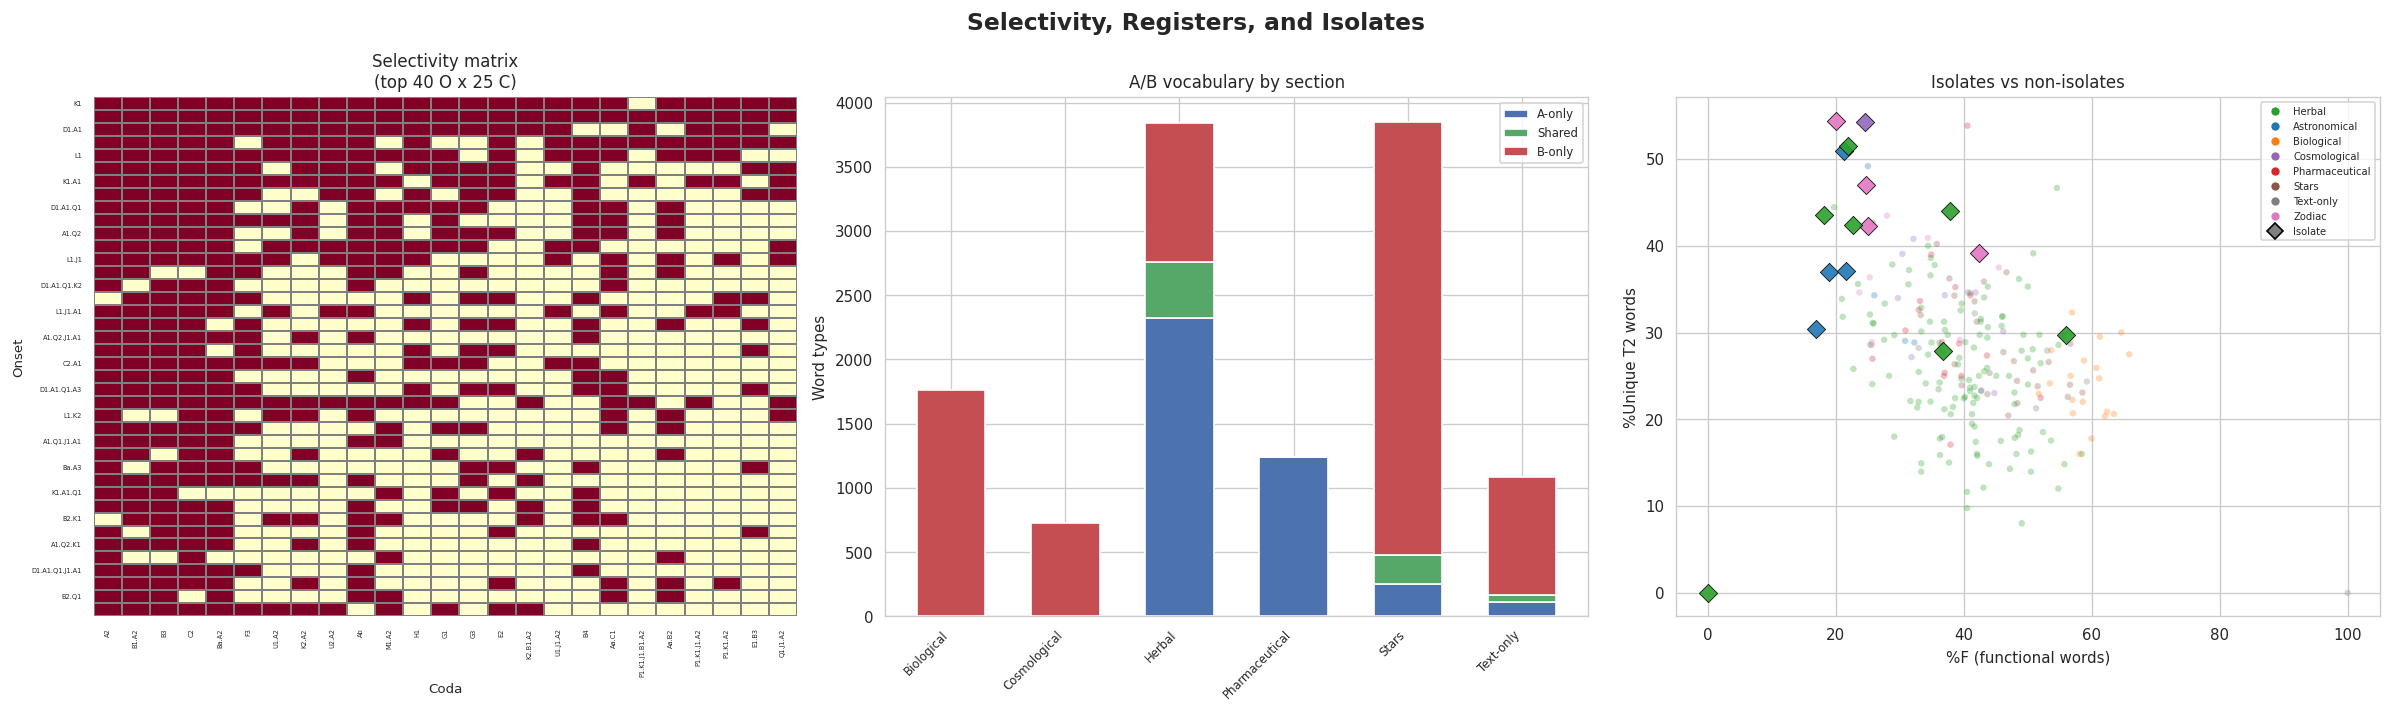

In [27]:
# Cell 13 — 3-panel figure

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle("Selectivity, Registers, and Isolates", fontsize=14, fontweight='bold')

# ── Panel 1: Clustered selectivity heatmap (top 40 onsets x top 25 codas) ──
ax1 = axes[0]
# Select top onsets/codas by total frequency in O-C pairs
onset_freq = Counter()
coda_freq = Counter()
for (o, c), n in oc_pairs.items():
    onset_freq['.'.join(o)] += n
    coda_freq['.'.join(c)] += n

top_onsets = [s for s, _ in onset_freq.most_common(40) if s in freq_filtered.index]
top_codas = [s for s, _ in coda_freq.most_common(25) if s in freq_filtered.columns]
sub_matrix = (freq_filtered.loc[top_onsets, top_codas] > 0).astype(int)

# Cluster rows and columns for ordering
if sub_matrix.shape[0] > 1 and sub_matrix.shape[1] > 1:
    row_dist = pdist(sub_matrix.values.astype(float), metric='euclidean')
    row_dist = np.nan_to_num(row_dist, nan=1.0)
    row_link = linkage(row_dist, method='ward')
    row_order = list(fcluster(row_link, t=sub_matrix.shape[0], criterion='maxclust'))
    row_sorted = [x for _, x in sorted(zip(row_order, sub_matrix.index))]

    col_dist = pdist(sub_matrix.values.T.astype(float), metric='euclidean')
    col_dist = np.nan_to_num(col_dist, nan=1.0)
    col_link = linkage(col_dist, method='ward')
    col_order = list(fcluster(col_link, t=sub_matrix.shape[1], criterion='maxclust'))
    col_sorted = [x for _, x in sorted(zip(col_order, sub_matrix.columns))]

    sub_matrix = sub_matrix.loc[row_sorted, col_sorted]

sns.heatmap(sub_matrix, ax=ax1, cmap='YlOrRd', cbar=False,
            linewidths=0.2, linecolor='grey')
ax1.set_title(f'Selectivity matrix\n(top {len(top_onsets)} O x {len(top_codas)} C)', fontsize=10)
ax1.set_xlabel('Coda', fontsize=8)
ax1.set_ylabel('Onset', fontsize=8)
ax1.tick_params(axis='both', labelsize=4)

# ── Panel 2: Stacked bar — A-only / shared / B-only by $I type ──
ax2 = axes[1]
i_types_ordered = sorted(vocab_by_IL.keys())
a_counts = []
s_counts = []
b_counts = []
labels = []
for itype in i_types_ordered:
    va = vocab_by_IL[itype]['A']
    vb = vocab_by_IL[itype]['B']
    inter = va & vb
    a_exc = len(va - vb)
    b_exc = len(vb - va)
    sh = len(inter)
    if a_exc + b_exc + sh == 0:
        continue
    labels.append(type_names.get(itype, itype))
    a_counts.append(a_exc)
    s_counts.append(sh)
    b_counts.append(b_exc)

x = np.arange(len(labels))
w = 0.6
ax2.bar(x, a_counts, w, label='A-only', color='#4c72b0')
ax2.bar(x, s_counts, w, bottom=a_counts, label='Shared', color='#55a868')
ax2.bar(x, b_counts, w, bottom=[a+s for a,s in zip(a_counts, s_counts)], label='B-only', color='#c44e52')
ax2.set_xticks(x)
ax2.set_xticklabels(labels, rotation=45, ha='right', fontsize=7)
ax2.set_ylabel('Word types')
ax2.set_title('A/B vocabulary by section', fontsize=10)
ax2.legend(fontsize=7)

# ── Panel 3: Scatter — isolates highlighted ──
ax3 = axes[2]
SECTION_COLORS = {'H':'#2ca02c','A':'#1f77b4','B':'#ff7f0e','C':'#9467bd',
                  'P':'#d62728','S':'#8c564b','T':'#7f7f7f','Z':'#e377c2','?':'#bcbd22'}

for fol, m in all_folio_metrics.items():
    itype = folio_data[fol]['meta'].get('I', '?')
    is_iso = fol in isolate_set
    color = SECTION_COLORS.get(itype, '#999999')
    marker = 'D' if is_iso else 'o'
    size = 60 if is_iso else 15
    alpha = 0.9 if is_iso else 0.3
    zorder = 10 if is_iso else 1
    ax3.scatter(m['pct_F']*100, m['pct_unique_t2']*100,
                c=color, marker=marker, s=size, alpha=alpha, zorder=zorder,
                edgecolors='black' if is_iso else 'none', linewidths=0.5 if is_iso else 0)

# Legend for sections
from matplotlib.lines import Line2D
legend_elements = [Line2D([0],[0], marker='o', color='w', markerfacecolor=c, markersize=6, label=type_names.get(k,k))
                   for k, c in SECTION_COLORS.items() if k in set(folio_data[f]['meta'].get('I','?') for f in folio_data)]
legend_elements.append(Line2D([0],[0], marker='D', color='w', markerfacecolor='grey',
                              markeredgecolor='black', markersize=7, label='Isolate'))
ax3.legend(handles=legend_elements, fontsize=6, loc='upper right')
ax3.set_xlabel('%F (functional words)', fontsize=9)
ax3.set_ylabel('%Unique T2 words', fontsize=9)
ax3.set_title('Isolates vs non-isolates', fontsize=10)

plt.tight_layout()
fig.savefig('images/selectivity_registers_isolates.png', bbox_inches='tight', dpi=150)
print("Saved: images/selectivity_registers_isolates.png")
plt.show()

## Conclusions

**Part A — Selectivity matrix**: The onset x coda combination space is highly selective (sparse). Clustered heatmap reveals blocks of onsets that share the same coda repertoire, confirming that positional slots are not freely combinable — there are co-occurrence constraints beyond simple position.

**Part B — Language A vs B vocabulary**: The A-only and B-only exclusive vocabularies differ in tier composition, testing whether Currier's "two languages" correspond to functional vs content registers. Jaccard overlap varies by illustration type, revealing which sections are most linguistically uniform.

**Part C — Isolated folios**: The 16 network isolates are characterized by unusual vocabulary that does not overlap with any community. Their tier structure and hapax rates quantify how anomalous they are relative to their illustration type.

In [28]:
# Cell 15 — Export to selectivity_registers_resultados.json

class NpEncoder(json.JSONEncoder):
    def default(self, obj):
        if isinstance(obj, (np.integer,)): return int(obj)
        if isinstance(obj, (np.floating,)): return float(obj)
        if isinstance(obj, (np.ndarray,)): return obj.tolist()
        if isinstance(obj, (np.bool_,)): return bool(obj)
        return super().default(obj)

results = {
    "part_a_selectivity": {
        "n_onset_syls": len(onset_labels_k),
        "n_coda_syls": len(coda_labels_k),
        "n_oc_pair_types": len(oc_pairs),
        "n_oc_pair_tokens": sum(oc_pairs.values()),
        "matrix_sparsity": round(sparsity, 4),
        "matrix_density_pct": round((1-sparsity)*100, 1),
        "top10_pairs": [
            {"onset": '.'.join(o), "coda": '.'.join(c), "freq": n}
            for (o, c), n in oc_pairs.most_common(10)
        ],
        "n_onset_blocks": n_groups if X_rows.shape[0] > 1 else 0,
        "onset_blocks": {
            int(grp): {
                "members": onset_groups[grp],
                "n_shared_codas": len(set(binary_matrix.columns).intersection(
                    *[set(binary_matrix.columns[binary_matrix.loc[m] == 1]) for m in onset_groups[grp]]
                )) if onset_groups[grp] else 0
            }
            for grp in sorted(onset_groups.keys())
        } if X_rows.shape[0] > 1 else {}
    },
    "part_b_register_vocabulary": {
        "lang_A_tokens": total_A,
        "lang_B_tokens": total_B,
        "a_only_types": len(a_only),
        "b_only_types": len(b_only),
        "shared_types": len(shared),
        "a_only_tokens": a_only_tokens,
        "b_only_tokens": b_only_tokens,
        "tier_analysis": {
            "a_only": tb_a,
            "b_only": tb_b,
        },
        "jaccard_by_section": {k: round(v, 4) for k, v in jaccard_by_I.items()},
    },
    "part_c_isolates": {
        "n_isolates": len(isolate_folios),
        "isolate_list": isolate_folios,
        "isolate_metrics": {
            fol: all_folio_metrics[fol] for fol in isolate_folios if fol in all_folio_metrics
        },
        "comparison": {
            metric: {
                "isolates_mean": round(np.mean([all_folio_metrics[f][metric] for f in isolate_folios if f in all_folio_metrics]), 4),
                "non_isolates_mean": round(np.mean([all_folio_metrics[f][metric] for f in folio_data if f not in isolate_set and f in all_folio_metrics]), 4),
            }
            for metric in ['pct_F', 'pct_OC', 'pct_T2', 'pct_unique_t2']
        }
    }
}

out_path = "resultados/selectivity_registers_resultados.json"
with open(out_path, "w") as f:
    json.dump(results, f, indent=2, cls=NpEncoder)
print(f"Exported: {out_path}")
print(f"Keys: {list(results.keys())}")

Exported: resultados/selectivity_registers_resultados.json
Keys: ['part_a_selectivity', 'part_b_register_vocabulary', 'part_c_isolates']
